<a href="https://colab.research.google.com/github/iliyadindar/DEEP/blob/main/week3/uzamsal_filtreler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Image Processing — Week 3: Uzamsal Filtreler (Spatial Filters)

**Grup: Nmertgules ve Iliya**

| Görev | Betik | Yapılan işlem |
| --- | --- | --- |
| 1 | `orijinal/soru1_dogrusal_olcekleme.py` | Min/max döngüyle bulunur, parlaklık [0, 255]'e doğrusal ölçeklenir (hazır fonksiyon yok) |
| 2 | `orijinal/soru2_histogram_esitleme.py` | 256 kutulu histogram → CDF → eşitleme tablosu (hazır fonksiyon yok) |
| 3 | `orijinal/soru3_clahe.py` | OpenCV CLAHE ve elle yazılmış CLAHE; birebir karşılaştırma |
| 4 | `orijinal/soru4_ortalama_filtre.py` | 3×3 ortalama çekirdeği konvolüsyonla; Gauss gürültüsü |
| 5 | `orijinal/soru5_medyan_filtre.py` | 5×5 medyan filtre, OpenCV ve elle; tuz-biber gürültüsü |
| 4 thread | `4_thread/cpu_parallel.py` | Aynı beş görev Numba ile derlenmiş döngülerde, 1 ve 4 iş parçacığı (thread) |

Bu notebook, grubun teslim ettiği betikleri **değiştirmeden** çalıştırır: her görevde önce ödevin istediği fonksiyonların kaynak kodu gösterilir, sonra betik aynen çalıştırılır (testleri ve ölçümleri çıktıda görünür), en sonda sonuç görüntüleri notebook içinde gösterilir.

**Çalıştırma:** repo içinden (VS Code / Jupyter) ya da Colab'da *Çalışma zamanı → Tümünü çalıştır*. Repo bulunamazsa (Colab) betikler GitHub'dan indirilir. GPU gerekmez.

## 0. Kurulum

In [1]:
import importlib.util, inspect, os, runpy, subprocess, sys, time
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

# Repo kökü çalışma klasöründen yukarı doğru aranır; bulunamazsa (ör. Colab) repo indirilir.
def repo_kokunu_bul():
    baslangic = Path.cwd().resolve()
    for klasor in [baslangic, *baslangic.parents]:
        if (klasor / 'week3' / 'orijinal' / 'soru1_dogrusal_olcekleme.py').is_file():
            return klasor
    return None

KOK = repo_kokunu_bul()
if KOK is None:
    subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/iliyadindar/DEEP.git'], check=True)
    KOK = Path('DEEP').resolve()

ORIJINAL = KOK / 'week3' / 'orijinal'
THREAD = KOK / 'week3' / '4_thread'
CIKTI = ORIJINAL / 'cikti'
CIKTI.mkdir(exist_ok=True)
# test_cpu.py, cpu_parallel modülünü içe aktarır. orijinal/ ve 4_thread/ klasörlerinde aynı adlı
# dosyalar (soru1_….py) olduğu için orijinal betikler aşağıda dosya yoluyla yüklenir.
if str(THREAD) not in sys.path:
    sys.path.insert(0, str(THREAD))

def modul_yukle(ad, dosya):
    spec = importlib.util.spec_from_file_location(ad, ORIJINAL / dosya)
    modul = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modul)
    return modul

INLINE = matplotlib.get_backend()
VARSAYILAN_RC = {k: v for k, v in matplotlib.rcParamsDefault.items() if k != 'backend'}

def calistir(betik, *argumanlar):
    """Betiği komut satırından çalıştırılmış gibi (__main__) çalıştırır.
    Betikler girdi yolunu sys.argv'den okur; Jupyter'in kendi argümanları karışmasın diye
    sys.argv betiğin adıyla değiştirilir. Kaydettikleri grafikler komut satırındakiyle aynı olsun
    diye matplotlib varsayılan ayarlarıyla çalışırlar; bazı betikler matplotlib'i 'Agg'e geçirdiği
    için sonrasında notebook'un satır içi gösterimi geri yüklenir."""
    eski = sys.argv
    sys.argv = [str(betik), *map(str, argumanlar)]
    t0 = time.perf_counter()
    try:
        with matplotlib.rc_context(VARSAYILAN_RC):
            runpy.run_path(str(betik), run_name='__main__')
    finally:
        sys.argv = eski
        matplotlib.use(INLINE)
        plt.close('all')
    print(f'\n[{Path(betik).name}: {time.perf_counter() - t0:.1f} s]')

def kaynak_goster(*fonksiyonlar):
    for f in fonksiyonlar:
        print(inspect.getsource(f))

def resimler(dosyalar, basliklar, histogram=False, boyut=3.6):
    goruntuler = [cv2.imread(str(CIKTI / d), cv2.IMREAD_GRAYSCALE) for d in dosyalar]
    satir = 2 if histogram else 1
    fig, eksenler = plt.subplots(satir, len(goruntuler), figsize=(boyut * len(goruntuler), boyut * satir * 0.8), squeeze=False)
    for i, (g, b) in enumerate(zip(goruntuler, basliklar)):
        eksenler[0, i].imshow(g, cmap='gray', vmin=0, vmax=255)
        eksenler[0, i].set_title(f'{b}\n[{g.min()}, {g.max()}]', fontsize=10)
        eksenler[0, i].axis('off')
        if histogram:
            eksenler[1, i].bar(np.arange(256), np.bincount(g.ravel(), minlength=256), width=1.0, color='0.3')
            eksenler[1, i].set_xlim(0, 255)
            eksenler[1, i].set_yticks([])
    fig.tight_layout()
    plt.show()

s1 = modul_yukle('soru1', 'soru1_dogrusal_olcekleme.py')
s2 = modul_yukle('soru2', 'soru2_histogram_esitleme.py')
s3 = modul_yukle('soru3', 'soru3_clahe.py')
s4 = modul_yukle('soru4', 'soru4_ortalama_filtre.py')
s5 = modul_yukle('soru5', 'soru5_medyan_filtre.py')
print(f'Repo: {KOK}')
print(f'Python {sys.version.split()[0]} · OpenCV {cv2.__version__} · NumPy {np.__version__}')

Repo: /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP
Python 3.12.3 · OpenCV 5.0.0 · NumPy 2.5.4


## 1. Test görüntüleri

`00_test_goruntusu_olustur.py`, sabit tohumlu (`default_rng(1907)`) sentetik bir sahne üretir; bu yüzden her çalıştırmada aynı girdiler ve aynı sonuçlar elde edilir:

* `orijinal_temiz.png`: gürültüsüz referans (PSNR hesabı için),
* `dusuk_kontrast.png`: dar parlaklık aralıklı girdi (Görev 1–3),
* `gurultulu_gauss.png`: σ = 20 Gauss gürültülü girdi (Görev 4),
* `tuz_biber.png`: piksellerin %5'i 0 ya da 255 (Görev 5).

Uretilen goruntuler (hepsi tek kanalli, 384x512):
  orijinal_temiz.png  min= 40 max=255
  dusuk_kontrast.png  min= 54 max=149  dinamik aralik=95/255
  gurultulu_gauss.png Gauss sigma=20
  tuz_biber.png       bozulan piksel=19461 (%9.9), yaklasik yarisi 0 yarisi 255

[00_test_goruntusu_olustur.py: 0.2 s]


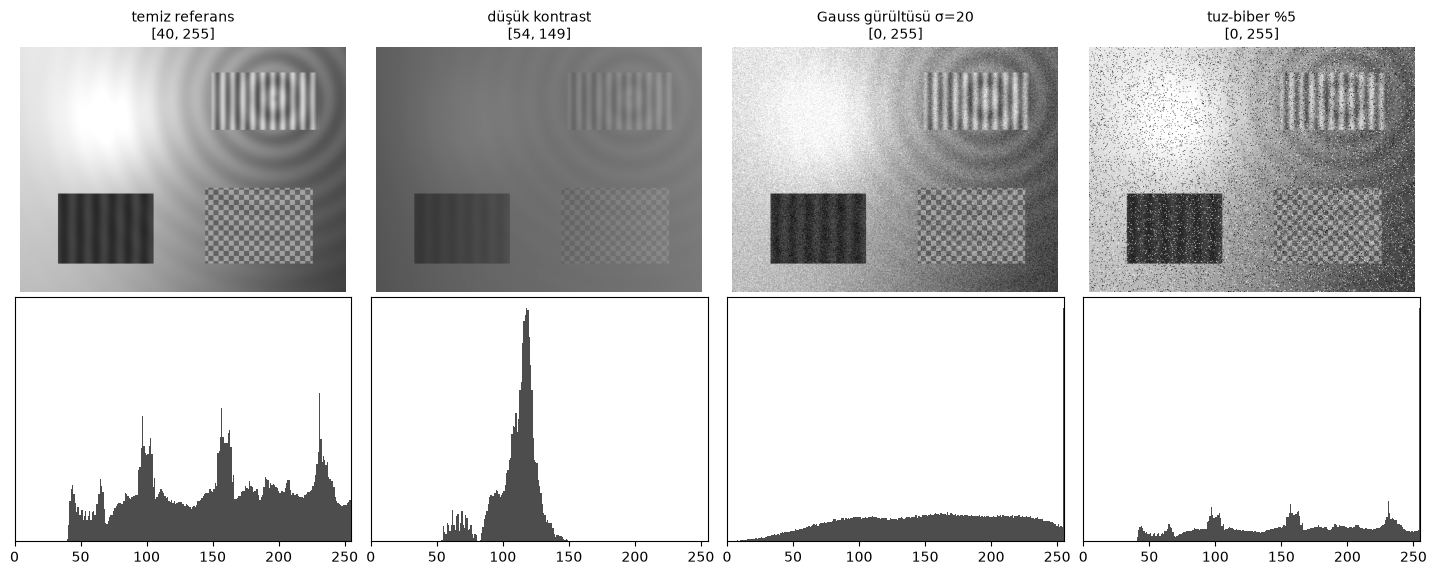

In [2]:
calistir(ORIJINAL / '00_test_goruntusu_olustur.py')
resimler(['orijinal_temiz.png', 'dusuk_kontrast.png', 'gurultulu_gauss.png', 'tuz_biber.png'],
         ['temiz referans', 'düşük kontrast', 'Gauss gürültüsü σ=20', 'tuz-biber %5'], histogram=True)

## 2. Görev 1 · Doğrusal kontrast germe

> *Düşük kontrastlı ve tek kanallı bir görüntüyü OpenCV kullanarak açınız. Bu görüntüdeki minimum ve maksimum değerleri bulunuz. Bulduğunuz bu değerleri kullanarak resimdeki parlaklık değerlerini [0, 255] aralığına doğrusal olarak ölçekleyiniz. Ölçekleme işlemi için hazır fonksiyon kullanmayınız.*

$$O(x,y) = 255 \cdot \frac{I(x,y) - \min}{\max - \min}$$

En küçük ve en büyük değer piksel piksel gezilerek bulunur; ölçekleme de döngüyle yapılır. Vektörel sürüm aynı sonucu hızlı verir. `cv2.normalize` yalnızca sonucu doğrulamak için kullanılır.

In [3]:
kaynak_goster(s1.min_max_bul_dongu, s1.dogrusal_olcekle_dongu)

def min_max_bul_dongu(img):
    """Goruntudeki en kucuk ve en buyuk piksel degerini dongu ile bulur."""
    satir, sutun = img.shape
    enkucuk = int(img[0, 0])
    enbuyuk = int(img[0, 0])

    for y in range(satir):
        for x in range(sutun):
            deger = int(img[y, x])
            if deger < enkucuk:
                enkucuk = deger
            if deger > enbuyuk:
                enbuyuk = deger

    return enkucuk, enbuyuk

def dogrusal_olcekle_dongu(img, enkucuk, enbuyuk):
    """Her pikseli tek tek gezerek [0,255] araligina tasir."""
    satir, sutun = img.shape
    cikis = np.zeros((satir, sutun), dtype=np.uint8)

    if enbuyuk == enkucuk:
        # Tum pikseller ayni: germe tanimsiz, sabit goruntu dondur
        return cikis

    olcek = 255.0 / (enbuyuk - enkucuk)

    for y in range(satir):
        for x in range(sutun):
            yeni = (int(img[y, x]) - enkucuk) * olcek
            # Yuvarlama + [0,255] sinirlama (saturasyon)
            yeni = int(yeni + 0.5)

Goruntu      : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/dusuk_kontrast.png
Boyut        : 384 x 512  (tek kanal, uint8)

Bulunan min  : 54
Bulunan max  : 149
Dinamik aralik (once): 95 / 255
  [OK] Dongu ile bulunan min/max, NumPy min/max ile ayni.

  [OK] Dongu surumu ile vektorel surum arasindaki maks. fark: 0

Sonuc min    : 0
Sonuc max    : 255
Dinamik aralik (sonra): 255 / 255
Standart sapma: 16.98 -> 45.59  (kontrast artisi)

Dogrulama (cv2.normalize referansi):
  maksimum fark = 0 seviye, ortalama fark = 0.0000 seviye
  (1 seviyelik farklar yalnizca yuvarlama kuralindan kaynaklanir.)

Kaydedildi   : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/soru1_dogrusal_olcekli.png

[soru1_dogrusal_olcekleme.py: 0.1 s]


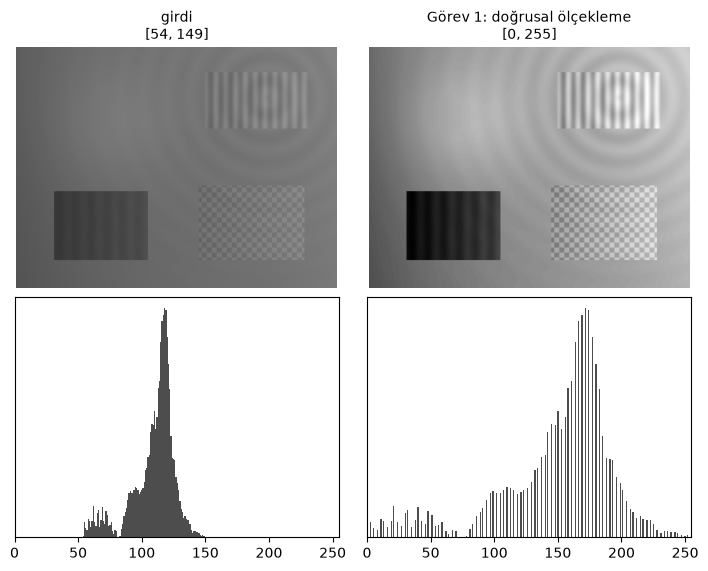

In [4]:
calistir(ORIJINAL / 'soru1_dogrusal_olcekleme.py')
resimler(['dusuk_kontrast.png', 'soru1_dogrusal_olcekli.png'], ['girdi', 'Görev 1: doğrusal ölçekleme'], histogram=True)

## 3. Görev 2 · Histogram eşitleme

> *Düşük kontrastlı ve tek kanallı bir görüntüyü OpenCV kullanarak açınız. Bu görüntüdeki değerlerin 256-değerli bir histogramını çıkarınız. Histogramdaki değerleri kullanarak Kümülatif Dağılım Değerlerini hesaplayınız. Bu dağılımı kullanarak histogram eşitleme işlemini gerçekleştiriniz. Çıktı resmi kaydediniz. Histogram çıkartma, CDF ve eşitleme işlemlerinde hazır fonksiyon kullanmayınız.*

$$h[v] = \#\{(x,y) : I(x,y) = v\}, \qquad cdf[v] = \sum_{k=0}^{v} h[k], \qquad LUT[v] = \operatorname{round}\left(255 \cdot \frac{cdf[v] - cdf_{min}}{N - cdf_{min}}\right)$$

`cdf_min` (sıfırdan farklı ilk CDF değeri) çıkarıldığı için en koyu piksel 0'a gider; formül `cv2.equalizeHist` ile aynıdır.

In [5]:
kaynak_goster(s2.histogram_hesapla, s2.cdf_hesapla, s2.esitleme_lut_olustur, s2.lut_uygula)

def histogram_hesapla(img):
    """Her piksel degerinin kac kez gectigini sayar. Hazir fonksiyon yok."""
    hist = [0] * L
    satir, sutun = img.shape

    for y in range(satir):
        for x in range(sutun):
            hist[int(img[y, x])] += 1

    return hist

def cdf_hesapla(hist):
    """cdf[v] = h[0] + h[1] + ... + h[v]. np.cumsum kullanilmadi."""
    cdf = [0] * L
    toplam = 0

    for v in range(L):
        toplam += hist[v]
        cdf[v] = toplam

    return cdf

def esitleme_lut_olustur(cdf, toplam_piksel):
    """CDF'den [0,255] araligina esleyen donusum tablosunu uretir."""
    # Sifirdan farkli ilk cdf degerini bul
    cdf_min = 0
    for v in range(L):
        if cdf[v] > 0:
            cdf_min = cdf[v]
            break

    payda = toplam_piksel - cdf_min
    lut = [0] * L

    if payda <= 0:
        # Goruntude tek bir gri seviye var -> esitleme anlamsiz
        return lut, cdf_min

    for v in range(L):
        if cdf[v] == 0:
            lut[v] = 0
          

Goruntu      : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/dusuk_kontrast.png
Boyut        : 384 x 512 = 196608 piksel

Histogram    : 256 kova, toplam = 196608 (piksel sayisina esit olmali: 196608)
               dolu kova sayisi = 94/256  (dusuk kontrastin gostergesi)
CDF          : cdf[255] = 196608 (toplam piksel sayisina esit olmali)
               cdf_min = 63

Sonuc        : min=0, max=255, dolu kova=75/256
Standart sapma: 16.98 -> 74.47

Dogrulama (cv2.equalizeHist referansi):
  maksimum fark = 0 seviye, ortalama fark = 0.0000 seviye, birebir ayni piksel = %100.00

Kaydedildi   : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/soru2_histogram_esitlenmis.png


Grafik       : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/soru2_histogram_grafik.png

[soru2_histogram_esitleme.py: 0.9 s]


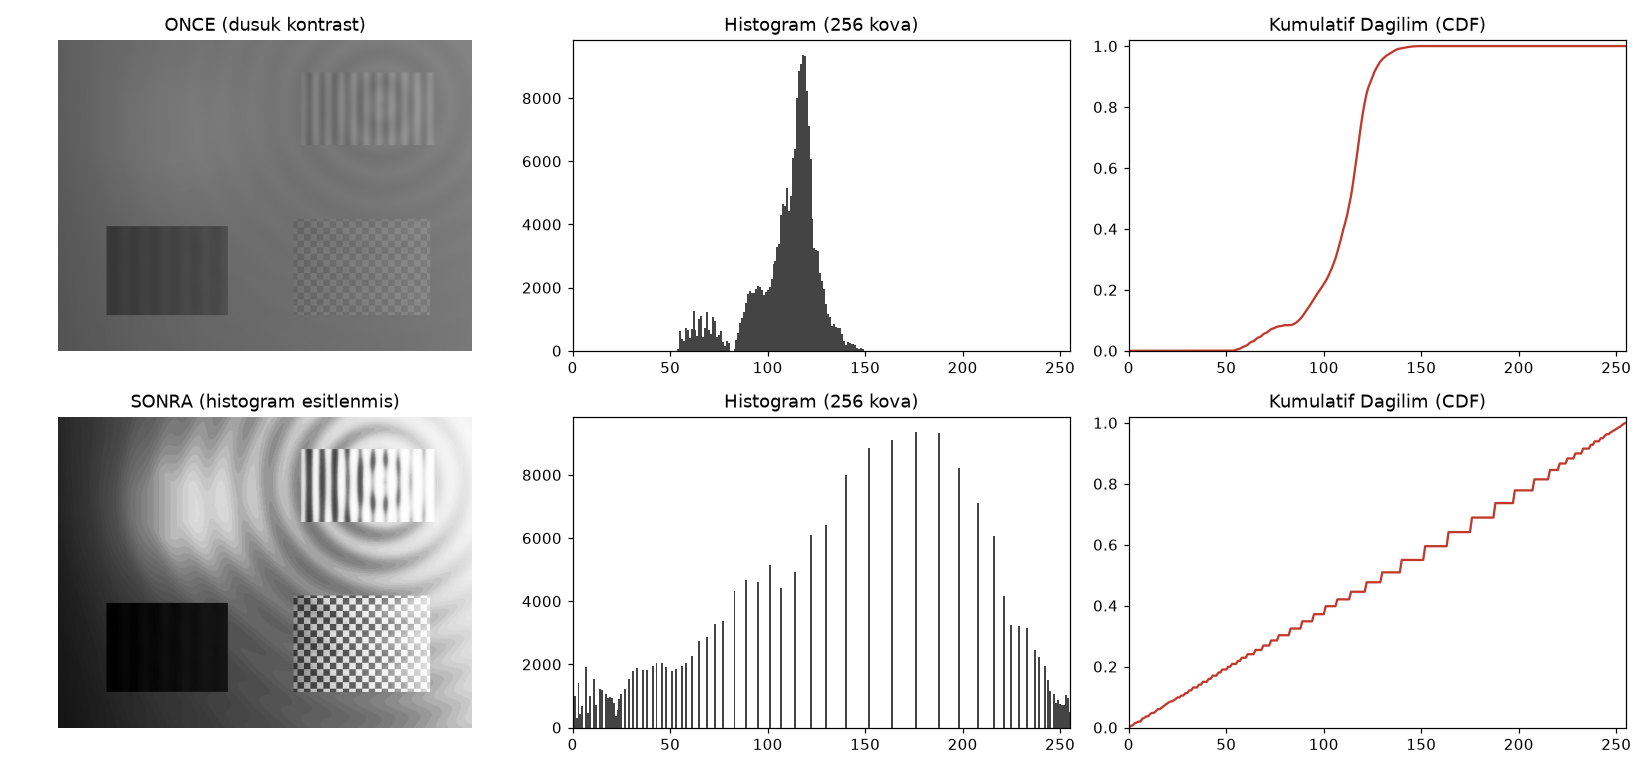

In [6]:
calistir(ORIJINAL / 'soru2_histogram_esitleme.py')
display(Image(filename=str(CIKTI / 'soru2_histogram_grafik.png')))

## 4. Görev 3 · CLAHE

İstenen (betiğin açıklamasındaki haliyle): düşük kontrastlı tek kanallı görüntüyü OpenCV'nin hazır CLAHE (Contrast Limited Adaptive Histogram Equalization) fonksiyonuyla düzeltmek, aynı işlemi hazır fonksiyon kullanmadan kendimiz gerçekleştirip test etmek.

Elle yazılan CLAHE, OpenCV'nin `cv::CLAHE` adımlarını aynen izler:

1. Görüntü 8×8 karoya bölünür (tam bölünmezse `BORDER_REFLECT_101` ile genişletilir).
2. Her karonun 256 kutulu histogramı çıkarılır.
3. **Kontrast sınırlama:** `clipLimit · karo_alanı / 256` eşiğini aşan kutular kesilir, kesilen sayım bütün kutulara eşit dağıtılır. CLAHE'yi AHE'den ayıran ve düz bölgelerde gürültünün aşırı büyümesini engelleyen adım budur.
4. Kesilmiş histogramın CDF'inden karo başına bir dönüşüm tablosu (LUT) hesaplanır.
5. Her piksel, çevresindeki dört karonun tablosuyla çift doğrusal (bilineer) ara değerlenir; karo sınırlarında basamak oluşmaz.

In [7]:
kaynak_goster(s3.clahe_manuel, s3.karo_lutlari_hesapla)

def clahe_manuel(img, clip_limit=2.0, tile_grid=(8, 8)):
    """OpenCV'nin cv2.createCLAHE(...).apply(img) karsiligi, elle gerceklenmis."""
    tilesX, tilesY = tile_grid
    h, w = img.shape

    # --- 1) Karo bolme icin gerekirse genislet ---
    alt = (tilesY - h % tilesY) % tilesY
    sag = (tilesX - w % tilesX) % tilesX
    gen = reflect101_genislet(img, alt, sag) if (alt or sag) else img

    lutlar, karo_w, karo_h, gercek_limit = karo_lutlari_hesapla(
        gen, tilesX, tilesY, clip_limit)

    cikis = bilineer_uygula(img, lutlar, karo_w, karo_h, tilesX, tilesY)
    return cikis, {"karo_w": karo_w, "karo_h": karo_h,
                   "gercek_limit": gercek_limit, "dolgu": (alt, sag)}

def karo_lutlari_hesapla(gen_img, tilesX, tilesY, clip_limit):
    """
    Genisletilmis goruntuden (tilesY, tilesX, 256) boyutunda LUT tablosu uretir.
    """
    gh, gw = gen_img.shape
    karo_w = gw // tilesX
    karo_h = gh // tilesY
    karo_alan = karo_w * karo_h

    # clipLimit'i karo a

Goruntu      : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/dusuk_kontrast.png
Boyut        : 384 x 512

Parametreler : clipLimit=8.0, tileGridSize=(8, 8)
               karo boyutu = 64 x 48 piksel
               gercek kesme esigi = 96 piksel/kova
               eklenen dolgu (alt, sag) = (0, 0)
Sure         : hazir=2.3 ms, manuel=46.8 ms

TEST - manuel gercekleme vs cv2.createCLAHE:
  ana goruntu                  maks fark=  0  ort fark=0.0000  birebir ayni=%100.00

Ek testler (farkli parametre ve boyutlar):
  clip=1.0, izgara=(4, 4)      maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  clip=2.0, izgara=(8, 8)      maks fark=  0  ort fark=0.0000  birebir ayni=%100.00


  clip=3.0, izgara=(8, 8)      maks fark=  0  ort fark=0.0000  birebir ayni=%100.00


  clip=4.0, izgara=(16, 16)    maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  clip=40.0, izgara=(2, 2)     maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  clip=0.0, izgara=(8, 8)      maks fark=  0  ort fark=0.0000  birebir ayni=%100.00


  500x377 (tam bolunmeyen)     maks fark=  0  ort fark=0.0000  birebir ayni=%100.00

SONUC: TUM TESTLER GECTI - manuel gercekleme OpenCV ile birebir ayni.

Kaydedildi   : cikti/soru3_clahe_opencv.png
               cikti/soru3_clahe_manuel.png


               cikti/soru3_ahe_sinirlamasiz.png (clipLimit=0, yani sinirlama yok)

Kontrast karsilastirmasi:
yontem                  global std   yerel kontrast
---------------------------------------------------
orijinal                     16.98             2.78
global HE                    74.47            14.25
CLAHE (manuel)               28.23            14.50
AHE (sinirlamasiz)           57.67            34.12

NOT: Global std CLAHE icin yaniltici bir olcuttur. CLAHE buyuk olcekli
parlaklik farkini bilerek bastirir (global std duser) ama YEREL detay
kontrastini yukseltir. Asil bakilmasi gereken sutun 'yerel kontrast'tir.
AHE'nin yerel kontrasti en yuksektir; ancak duz bolgelerdeki gurultuyu de
yukselttigi icin CLAHE tercih edilir (kontrast sinirlamasinin amaci budur).



clipLimit tarama grafigi: /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/soru3_cliplimit_taramasi.png
  Dusuk clipLimit -> donusum birim fonksiyona yaklasir (etki az).
  Yuksek clipLimit -> AHE'ye yaklasir, gurultu de yukselir.

[soru3_clahe.py: 1.3 s]


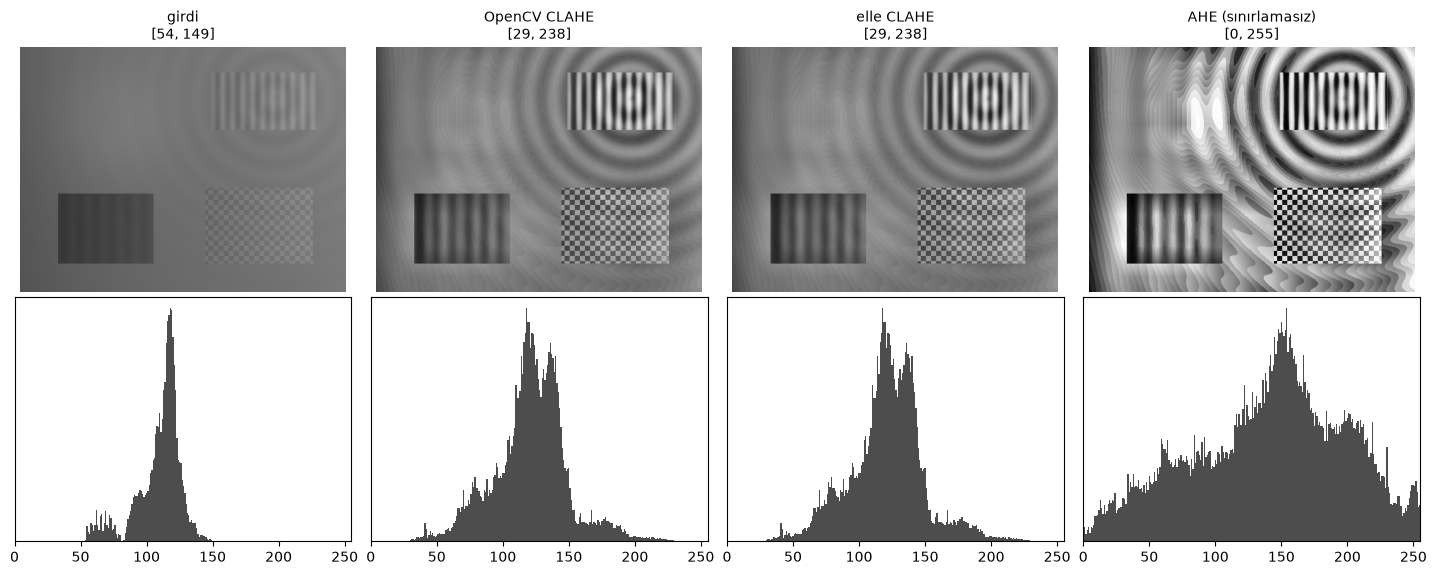

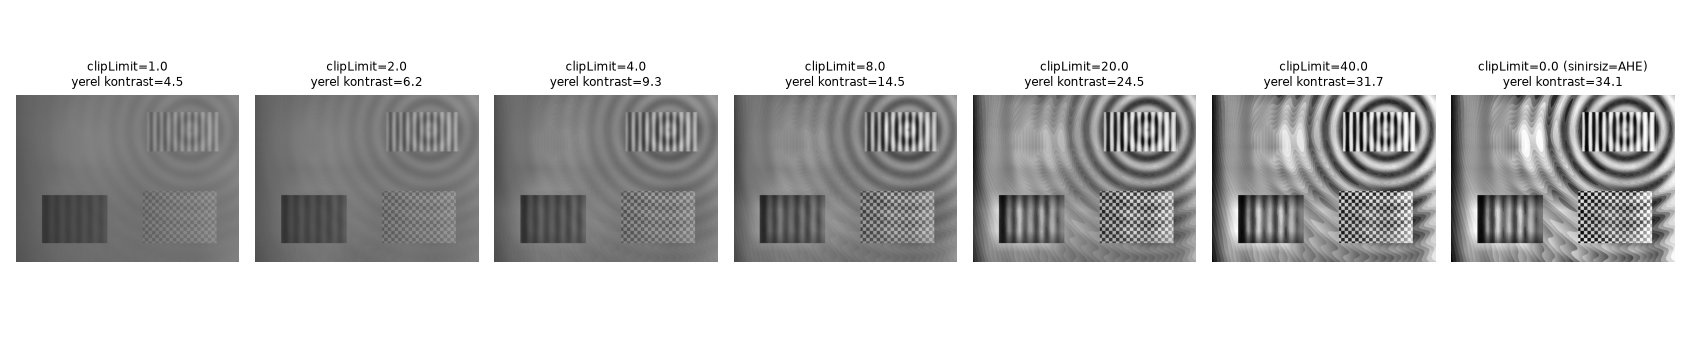

In [8]:
calistir(ORIJINAL / 'soru3_clahe.py')
resimler(['dusuk_kontrast.png', 'soru3_clahe_opencv.png', 'soru3_clahe_manuel.png', 'soru3_ahe_sinirlamasiz.png'],
         ['girdi', 'OpenCV CLAHE', 'elle CLAHE', 'AHE (sınırlamasız)'], histogram=True)
display(Image(filename=str(CIKTI / 'soru3_cliplimit_taramasi.png')))

## 5. Görev 4 · 3×3 ortalama filtre (konvolüsyon)

$$K = \frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix}, \qquad O(x,y) = \sum_{i,j} K(i,j)\, I(x-j,\, y-i)$$

Konvolüsyonda çekirdek 180° döndürülür; ortalama çekirdeği simetrik olduğu için korelasyonla aynı sonuç çıkar, kodda yine de döndürme açıkça yapılır. Kenarlar `reflect101` ile genişletilir (OpenCV'nin varsayılanı). Döngülü sürüm her piksel ve her çekirdek elemanı için iç içe döngüdür; vektörel sürüm kaydırılmış dilimleri toplar.

In [9]:
kaynak_goster(s4.kenar_genislet, s4.konvolusyon_dongu)

def kenar_genislet(img, pad, mod="reflect101"):
    """Goruntunun dort yanina 'pad' kadar dolgu ekler."""
    h, w = img.shape
    cikis = np.zeros((h + 2 * pad, w + 2 * pad), dtype=np.float64)
    cikis[pad:pad + h, pad:pad + w] = img

    def esle(i, n):
        """Disari tasan i indeksini [0, n-1] araligina katlar."""
        if mod == "replicate":
            return min(max(i, 0), n - 1)
        # reflect101: kenar pikseli tekrarlanmaz
        if n == 1:
            return 0
        while i < 0 or i >= n:
            if i < 0:
                i = -i
            if i >= n:
                i = 2 * (n - 1) - i
        return i

    for y in range(h + 2 * pad):
        for x in range(w + 2 * pad):
            if pad <= y < pad + h and pad <= x < pad + w:
                continue
            cikis[y, x] = img[esle(y - pad, h), esle(x - pad, w)]

    return cikis

def konvolusyon_dongu(img, cekirdek, mod="reflect101"):
    """
    Cekirdegi 180 derece dondurup goruntu uzerinde gezdirir.


Gurultulu goruntu : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/gurultulu_gauss.png
Boyut             : 384 x 512

3x3 ortalama cekirdegi (her eleman = 1/9 = 0.1111):
   [0.1111  0.1111  0.1111]
   [0.1111  0.1111  0.1111]
   [0.1111  0.1111  0.1111]
   cekirdek toplami = 1.0000  (1.0 olmali -> parlaklik korunur)



Sure              : dongu=0.45 s, vektorel=12.1 ms
  [OK] Dongu ve vektorel surum arasindaki maks. fark: 0

Dogrulama (OpenCV referanslari):
  cv2.blur(3,3)    maks fark= 0  ort fark=0.0000  birebir ayni=%100.00
  cv2.filter2D     maks fark= 0  ort fark=0.0000  birebir ayni=%100.00

Gurultu bastirma olcumleri:
goruntu                            MSE   PSNR (dB)
--------------------------------------------------
gurultulu (filtresiz)           378.85       22.35
3x3 ortalama filtre              77.16       29.26
5x5 ortalama filtre              77.30       29.25
3x3 Gauss (karsilastirma)        74.87       29.39
3x3 medyan (karsilastirma)       79.95       29.10

YORUM:
* Ortalama filtre Gauss gurultusu icin dogru aractir: bagimsiz gurultu
  orneklerinin ortalamasi alindigi icin gurultu standart sapmasi ~1/sqrt(9)
  oraninda duser. Burada 3x3 ortalama ~+6.9 dB kazandiriyor.
* 5x5 daha cok gurultu bastirir ama kenarlari da daha cok bulaniklastirir;
  bu goruntude iki etki birbirini gotur

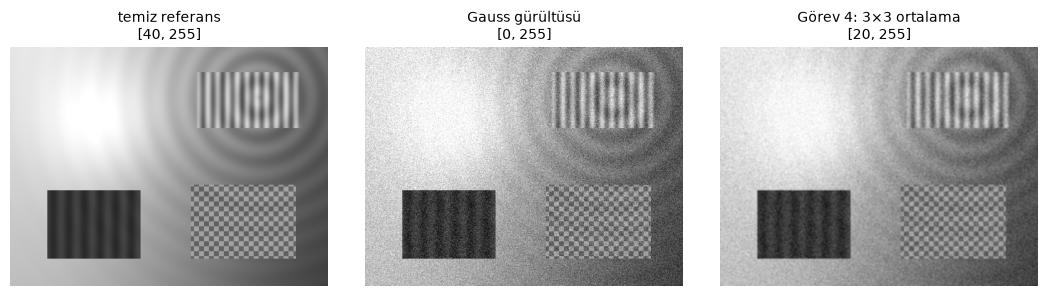

In [10]:
calistir(ORIJINAL / 'soru4_ortalama_filtre.py')
resimler(['orijinal_temiz.png', 'gurultulu_gauss.png', 'soru4_ortalama_3x3.png'],
         ['temiz referans', 'Gauss gürültüsü', 'Görev 4: 3×3 ortalama'])

## 6. Görev 5 · 5×5 medyan filtre

Her piksel için 5×5 komşuluktaki 25 değer sıralanır ve ortadaki (13.) değer yazılır. Tuz-biber gürültüsü aykırı değer (0 ya da 255) üretir: ortalama filtre bu değeri 5×5 alana yayar, medyan ise sıralamanın ucundaki değeri hiç seçmez. Elle yazılan sürüm sıralamayı **eklemeli sıralama** (insertion sort) ile yapar; küçük dizilerde (25 eleman) pratikte en hızlısıdır. Medyan doğrusal değildir, konvolüsyonla yazılamaz.

In [11]:
kaynak_goster(s5.medyan_bul, s5.medyan_filtre_dongu)

def medyan_bul(pencere):
    """
    Verilen listenin medyanini EKLEMELI SIRALAMA (insertion sort) ile bulur.
    Kucuk diziler (25 eleman) icin eklemeli siralama pratikte en hizlisidir.
    """
    n = len(pencere)
    for i in range(1, n):
        anahtar = pencere[i]
        j = i - 1
        while j >= 0 and pencere[j] > anahtar:
            pencere[j + 1] = pencere[j]
            j -= 1
        pencere[j + 1] = anahtar
    return pencere[n // 2]     # 25 eleman -> indeks 12 (ortadaki)

def medyan_filtre_dongu(img, k=5):
    """Her piksel icin 5x5 pencereyi toplayip elle siralar, ortancayi yazar."""
    assert k % 2 == 1, "Cekirdek boyutu tek sayi olmali"
    pad = k // 2
    gen = replicate_genislet(img, pad)
    h, w = img.shape
    cikis = np.zeros((h, w), dtype=np.uint8)

    for y in range(h):
        # Satiri Python listesine cevirmek ic donguyu belirgin hizlandirir
        bloklar = [gen[y + i].tolist() for i in range(k)]
        satir_cikis = cikis[y]
        for x in range

Gurultulu goruntu : /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/tuz_biber.png
Boyut             : 384 x 512
Tuz-biber izi     : 9927 adet 0 (biber), 13372 adet 255 (tuz)



Sure              : hazir=0.3 ms, manuel-vektorel=63.6 ms, manuel-dongu=1.21 s

TEST - elle yazilan filtre vs cv2.medianBlur(5):
  manuel (acik dongu)                maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  manuel (vektorel)                  maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  dongu vs vektorel (ic tutarlilik)  maks fark=  0  ort fark=0.0000  birebir ayni=%100.00

Ek testler:
  rastgele 37x53                     maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  tek satir 1x40                     maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  kucuk 3x3                          maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  sabit goruntu                      maks fark=  0  ort fark=0.0000  birebir ayni=%100.00
  3x3 cekirdek (ana goruntu)         maks fark=  0  ort fark=0.0000  birebir ayni=%100.00

SONUC: TUM TESTLER GECTI - elle yazilan filtre OpenCV ile birebir ayni.

Gurultu bastirma olcumleri (tuz-biber gurultusu uzerinde):
goru

%10                   14.97    36.39    35.21   3x3
%20                   11.98    29.73    32.31   5x5
%30                   10.23    23.46    30.32   5x5


%40                    8.97    18.70    28.11   5x5
%45                    8.44    16.65    26.20   5x5

Beklendigi gibi: dusuk yogunlukta kucuk pencere (daha az detay kaybi),
yogun gurultude buyuk pencere kazanir (pencerenin yarisindan fazlasinin
bozulma olasiligi kucuk pencerede hizla artar).

Kaydedildi        : cikti/soru5_medyan_opencv.png
                    cikti/soru5_medyan_manuel.png
                    cikti/soru5_ortalama5x5_karsilastirma.png

[soru5_medyan_filtre.py: 1.9 s]


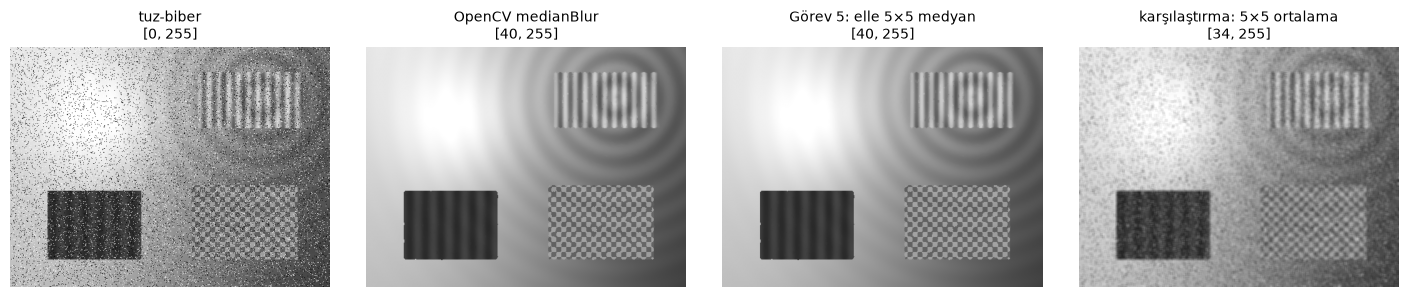

In [12]:
calistir(ORIJINAL / 'soru5_medyan_filtre.py')
resimler(['tuz_biber.png', 'soru5_medyan_opencv.png', 'soru5_medyan_manuel.png', 'soru5_ortalama5x5_karsilastirma.png'],
         ['tuz-biber', 'OpenCV medianBlur', 'Görev 5: elle 5×5 medyan', 'karşılaştırma: 5×5 ortalama'])

## 7. Bütün görevlerin karşılaştırması

`06_karsilastirma_gorseli.py` beş görevin çıktılarını iki özet panelde toplar.

Kaydedildi: /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/00_kontrast_karsilastirma.png


Kaydedildi: /mnt/c/Users/iliad/Downloads/Sinav_6Kasim/DEEP/week3/orijinal/cikti/00_gurultu_karsilastirma.png

[06_karsilastirma_gorseli.py: 1.9 s]


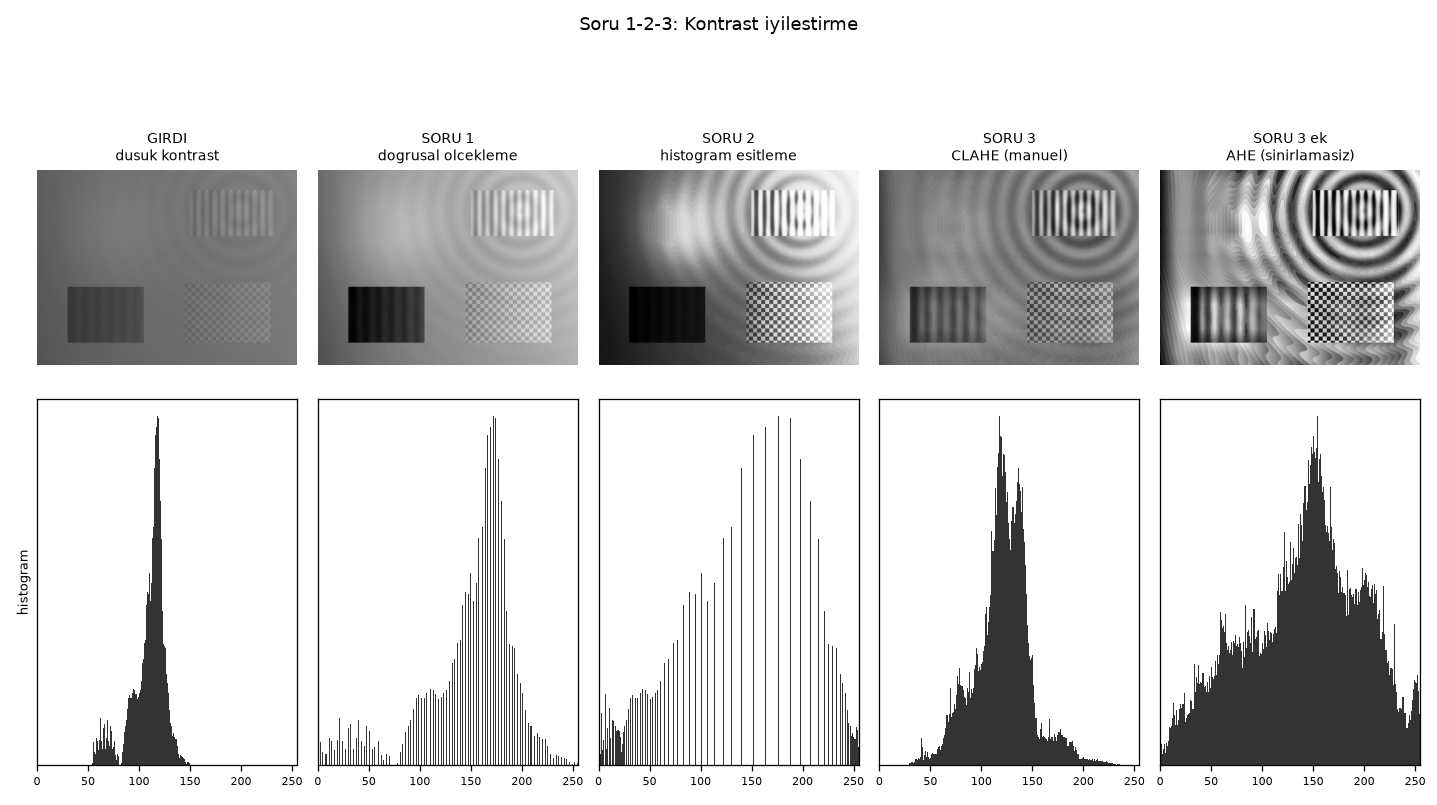

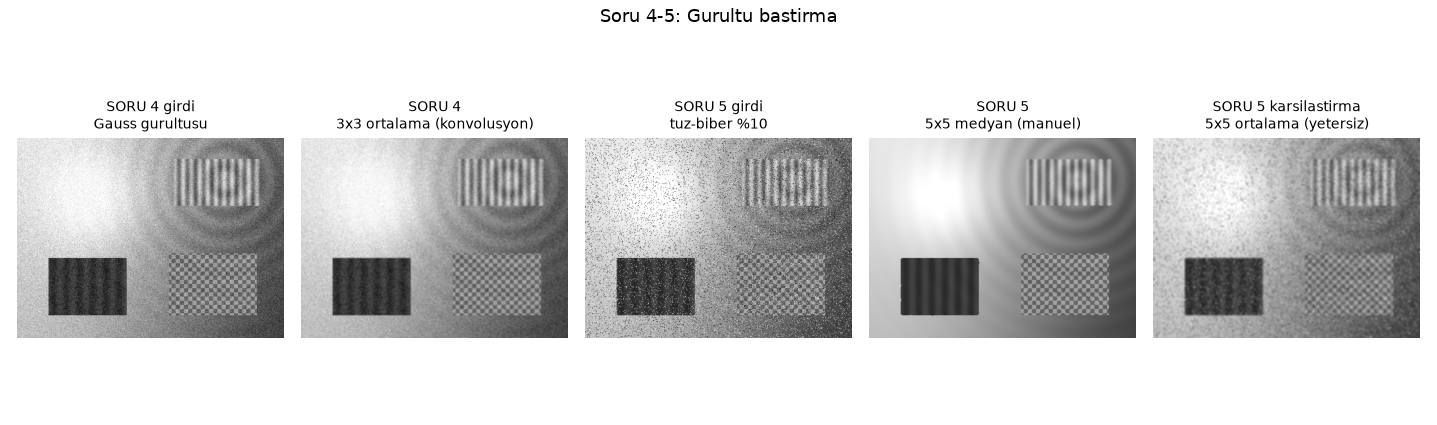

In [13]:
calistir(ORIJINAL / '06_karsilastirma_gorseli.py')
display(Image(filename=str(CIKTI / '00_kontrast_karsilastirma.png')))
display(Image(filename=str(CIKTI / '00_gurultu_karsilastirma.png')))

## 8. 4 thread sürümü

`4_thread/cpu_parallel.py` aynı beş görevi Numba ile yerel CPU koduna derlenmiş döngülerle yapar; `set_num_threads(4)` dört işçi (worker) seçer ve `prange` döngüleri bu işçilere bölünür:

* **Histogram:** her iş parçacığı görüntünün kendi parçasında **kendi yerel histogramını** sayar, sonunda parçalar toplanır. Aynı sayaca iki iş parçacığı yazmadığı için yarış durumu (race condition) oluşmaz.
* **CLAHE:** karoların tabloları ve çıkış pikselleri paralel hesaplanır; küçük CDF ve son birleştirme adımları sıralıdır.
* **Ortalama ve medyan:** her çıkış satırı bağımsızdır, satırlar işçilere dağıtılır.

`test_cpu.py`, her görevi aynı derlenmiş kodla 1 ve 4 işçiyle çalıştırır (her süre 9 ölçümün ortancası, ilk çağrı derlemeyi dışarıda bırakmak için ısınmadır), sonucu OpenCV ile karşılaştırır ve kenar durumlarını test eder.

In [14]:
calistir(THREAD / 'test_cpu.py')

{'task': 1, 'max_difference_opencv': 0, 'one_thread_ms': 0.3226718000405526, 'four_threads_ms': 0.15446480001628515, 'speedup': 2.0889665477606125}


{'task': 2, 'max_difference_opencv': 0, 'one_thread_ms': 0.20400120001795585, 'four_threads_ms': 0.08202479993997258, 'speedup': 2.487067328018454}


{'task': 3, 'max_difference_opencv': 0, 'one_thread_ms': 2.677674400001706, 'four_threads_ms': 0.6856453999716905, 'speedup': 3.9053341568575597}


{'task': 4, 'max_difference_opencv': 0, 'one_thread_ms': 8.129812199968, 'four_threads_ms': 2.2438615999817557, 'speedup': 3.6231344214964514}


{'task': 5, 'max_difference_opencv': 0, 'one_thread_ms': 43.24482699994405, 'four_threads_ms': 12.179381999976613, 'speedup': 3.550658563794706}


Native worker IDs: [0 1 2 3] layer: omp


CPU TESTS PASS



[test_cpu.py: 14.0 s]


In [15]:
import json
rapor = json.loads((THREAD / 'results' / 'cpu_results.json').read_text())
print(f"İşçi kimlikleri: {rapor['cpu_workers']} · threading katmanı: {rapor['threading_layer']}\n")
print(f"{'Görev':<32} {'1 thread (ms)':>13} {'4 thread (ms)':>13} {'hızlanma':>9} {'OpenCV farkı':>12}")
adlar = {1: 'Doğrusal ölçekleme', 2: 'Histogram eşitleme', 3: 'CLAHE', 4: '3×3 ortalama', 5: '5×5 medyan'}
for r in rapor['main_results']:
    print(f"{r['task']} · {adlar[r['task']]:<28} {r['one_thread_ms']:13.3f} {r['four_threads_ms']:13.3f} {r['speedup']:8.2f}× {r['max_difference_opencv']:12d}")
print(f"\nEk kenar testleri: {len(rapor['edge_tests'])} durum, en büyük fark {max(e['max_difference'] for e in rapor['edge_tests'])}")

İşçi kimlikleri: [0, 1, 2, 3] · threading katmanı: omp

Görev                            1 thread (ms) 4 thread (ms)  hızlanma OpenCV farkı
1 · Doğrusal ölçekleme                   0.323         0.154     2.09×            0
2 · Histogram eşitleme                   0.204         0.082     2.49×            0
3 · CLAHE                                2.678         0.686     3.91×            0
4 · 3×3 ortalama                         8.130         2.244     3.62×            0
5 · 5×5 medyan                          43.245        12.179     3.55×            0

Ek kenar testleri: 28 durum, en büyük fark 1


## 9. Sonuç

* **Görev 1–3 (kontrast):** doğrusal ölçekleme dar aralığı [0, 255]'e açar ama histogramın biçimini değiştirmez; histogram eşitleme parlaklıkları CDF'e göre yeniden dağıtır; CLAHE yerel kontrastı artırır ve kontrast sınırlaması sayesinde düz bölgelerde gürültüyü AHE kadar büyütmez. Üç elle yazılmış uygulama da OpenCV ile birebir aynı sonucu verir (çıktılardaki "maks fark" değerleri).
* **Görev 4–5 (gürültü):** Gauss gürültüsünde 3×3 ortalama PSNR'yi yükseltir; tuz-biber gürültüsünde 5×5 medyan darbeleri tamamen siler, aynı boyuttaki ortalama filtre ise darbeleri komşulara yayar. İki elle yazılmış filtre de OpenCV ile aynıdır.
* **4 thread:** 1 ve 4 işçinin çıktıları aynıdır. Hızlanma işe bağlıdır: medyan ve konvolüsyon gibi piksel başına çok iş yapan görevler belirgin hızlanır, tek geçişlik doğrusal ölçeklemede iş parçacığı yönetiminin maliyeti kazancı yiyebilir. Süreler makineye ve yüke göre değişir.